In [36]:
import pandas as pd #libary to work with data
import seaborn as sns #library for plotting
import numpy as np #library for working with numerical data
import matplotlib.pyplot as plt #Basis for seaborn
from sklearn.linear_model import LinearRegression #Model of choice

In [37]:
#Downloaded CSV from kaggle https://www.kaggle.com/datasets/rajatkumar30/streaming-application-viewership
df = pd.read_csv('streaming_viewership_data.csv').dropna()

feature_names = ["Duration_Watched (minutes)", "Genre", "Age", "Gender", "Subscription_Status", "Languages"] #Chosen features to work with, features defined as relevant variables
bin_features = ["Genre", "Gender", "Subscription_Status", "Languages"]
num_features = ["Duration_Watched (minutes)", "Age"]
target_feature = ["Ratings"]
X = df[feature_names]
Y = df[target_feature]

In [38]:
#Code from a previous github project, altered slightly
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('bin', OneHotEncoder(drop='first'), bin_features)
    ]
)

In [39]:
#Split training and testing set, set testing set size to
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    Y,
    test_size=0.25,
)

In [40]:
from sklearn.linear_model import LinearRegression
X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)
model = LinearRegression()
model.fit(X_train_scaled, y_train)

y_test_pred = model.predict(X_test_scaled)
y_train_pred = model.predict(X_train_scaled)

In [41]:
#Use cost function to predict accuracy, low MSE, better model!
from sklearn.metrics import mean_squared_error, root_mean_squared_error
print(f"MSE training data: {mean_squared_error(y_train,y_train_pred)}")
print(f"MSE testing data: {mean_squared_error(y_test,y_test_pred)}")


MSE training data: 1.9660063707317872
MSE testing data: 1.9732500366916386


In [57]:
print(f"Side-by-side prediction accuracy test!")
#Appropriate and HEAVILY altered code from CodeHS learning modules
y_test = np.array(y_test).reshape(-1,1)
y_test_pred = np.array(y_test_pred).reshape(-1,1)
X_test = np.array(X_test).reshape(-1,6)
for index in range(len(X_test)):
    actual = y_test[index] #gets the actual y value from the ytest dataset
    predicted_y = y_test_pred[index] #gets the predicted y value from the predict variable
    x_coord = X_test[index] #gets the x value from the xtest dataset
    print("Inputs:", x_coord, "\nPredicted y value:", predicted_y, "Actual y value:", actual, "\n")

Side-by-side prediction accuracy test!
Inputs: [72.94282731 'Documentary' 17 'Female' 'Free' 'English'] 
Predicted y value: [2.92111395] Actual y value: [4] 

Inputs: [25.72818881 'Sci-Fi' 67 'Female' 'Premium' 'English'] 
Predicted y value: [2.97830378] Actual y value: [2] 

Inputs: [31.3111357 'Action' 21 'Female' 'Premium' 'Spanish'] 
Predicted y value: [2.96697426] Actual y value: [4] 

Inputs: [28.1880884 'Comedy' 62 'Male' 'Premium' 'Chinese'] 
Predicted y value: [2.97229461] Actual y value: [4] 

Inputs: [118.4726117 'Comedy' 27 'Male' 'Free' 'Spanish'] 
Predicted y value: [2.9890085] Actual y value: [4] 

Inputs: [1.102820799 'Documentary' 69 'Male' 'Premium' 'English'] 
Predicted y value: [2.86972279] Actual y value: [4] 

Inputs: [13.08667227 'Sci-Fi' 23 'Male' 'Premium' 'German'] 
Predicted y value: [2.83983529] Actual y value: [4] 

Inputs: [86.61719526 'Drama' 39 'Male' 'Free' 'German'] 
Predicted y value: [3.04337457] Actual y value: [3] 

Inputs: [34.36277143 'Comedy' 37

Inputs: [72.94282731 'Documentary' 17 'Female' 'Free' 'English'] 
Predicted y value: [2.92111395] Actual y value: [4] 

Inputs: [25.72818881 'Sci-Fi' 67 'Female' 'Premium' 'English'] 
Predicted y value: [2.97830378] Actual y value: [2] 

Inputs: [31.3111357 'Action' 21 'Female' 'Premium' 'Spanish'] 
Predicted y value: [2.96697426] Actual y value: [4] 

Inputs: [28.1880884 'Comedy' 62 'Male' 'Premium' 'Chinese'] 
Predicted y value: [2.97229461] Actual y value: [4] 

Inputs: [118.4726117 'Comedy' 27 'Male' 'Free' 'Spanish'] 
Predicted y value: [2.9890085] Actual y value: [4] 

Inputs: [1.102820799 'Documentary' 69 'Male' 'Premium' 'English'] 
Predicted y value: [2.86972279] Actual y value: [4] 

Inputs: [13.08667227 'Sci-Fi' 23 'Male' 'Premium' 'German'] 
Predicted y value: [2.83983529] Actual y value: [4] 

Inputs: [86.61719526 'Drama' 39 'Male' 'Free' 'German'] 
Predicted y value: [3.04337457] Actual y value: [3] 

Inputs: [34.36277143 'Comedy' 37 'Male' 'Premium' 'Chinese'] 
Predicted

Duration_Watched (minutes)
Pearson's Correlation: r = 0.010902303750305577


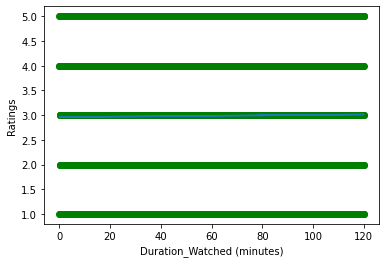

Age
Pearson's Correlation: r = 0.008028200551885968


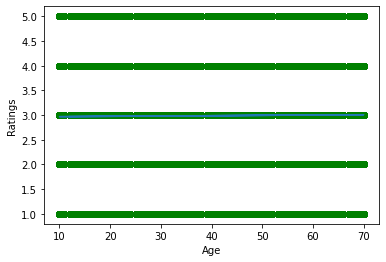

In [65]:
import matplotlib.pyplot as plt

#Loop through the numerical features, and make matplotlibs of them
#Note I did not include categorical features
for i in range(len(num_features)):
    print(num_features[i])
    x = df[num_features[i]]
    y = df[target_feature[0]]
    plt.scatter(x, y ,c= "green")
    plt.xlabel(num_features[i])
    plt.ylabel(target_feature[0])
    m, b = np.polyfit(x, y, 1)
    plt.plot(x, m*x + b)
    print("Pearson's Correlation: r =", x.corr(y))
    plt.show()